# Analyzing SKIRT outputs

After the simulation has finished running, observables such as band flux and luminosity can be readily extracted from the output files. The bands supported by SKIRT and their central wavelengths are:

| Band | Wavelength (micron)|
| :--- | ---: |
| GALEX_FUV | 0.1535079263 |
| GALEX_NUV | 0.2300784642 |
| SDSS_u | 0.3556457276 |
| SDSS_g | 0.4702444002 |
| SDSS_r | 0.6175540451 |
| SDSS_i | 0.748994523 |
| SDSS_z | 0.8946683031 |
| 2MASS_J | 1.239286141 |
| 2MASS_H | 1.649435452 |
| 2MASS_Ks | 2.163824108 |
| WISE_W1 | 3.389693501 |
| WISE_W2 | 4.640627423 |
| WISE_W3 | 12.56759007 |
| WISE_W4 | 22.31422389 |
| HERSCHEL_PACS70 | 70.76977781 |
| HERSCHEL_PACS100 | 100.80266 |
| HERSCHEL_PACS160 | 161.892196 |
| HERSCHEL_SPIRE250 | 252.5495116 |
| HERSCHEL_SPIRE350 | 354.2725745 |
| HERSCHEL_SPIRE500 | 515.3633266 |


In [23]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import SKIRT_tools
import SKIRT_tools.skirt_tools as sktools

rundir = "/nfspool-0/home/jennydw/SKIRT-tools/tutorials/example" # Absolute path
name = "m12f_mass56000_cr_700"

# The instrument specifies the projection. The default projections are xy, yz, and xz.
instrument_name = "xy"

# Returns dictionary of fluxes in different bands
flux_dict = sktools.get_band_flux(name, rundir, instrument_name, bands=["SDSS_r"])
# Returns dictioanry of luminosity in different bands
lum_dict = sktools.get_luminosity(name, rundir, bands=['SDSS_r'])
print("Flux in r-band with dust:", flux_dict["SDSS_r"]["total"])
print("Flux in r-band w/o dust:", flux_dict["SDSS_r"]["transparent"])
print("Luminosity in r-band (Lsun):", lum_dict["SDSS_r"])


/nfspool-0/home/jennydw/SKIRT-tools/tutorials/example/m12f_mass56000_cr_700_xy_sed.dat
Flux in r-band with dust: 0.04869799487990632 Jy
Flux in r-band w/o dust: 0.1586021819830529 Jy
Luminosity in r-band (Lsun): 10021530340.0


# Creating Mock Images

Like extracting the flux and luminosity, creating a mock image is pretty simple. The weights are arbitrary, you can adjust according to what produces the prettiest pictures. For actual data analysis, use the band flux/luminosity calculations.

maxden ==  1.9161826 dynrange ==  100 minden ==  0.019161826


/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:71: RuntimeWarning: divide by zero encountered in log
  r = np.log(r/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:72: RuntimeWarning: divide by zero encountered in log
  g = np.log(g/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:73: RuntimeWarning: divide by zero encountered in log
  b = np.log(b/minnorm) / np.log(maxnorm/minnorm)


maxden ==  1.484081 dynrange ==  100 minden ==  0.014840811


/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:71: RuntimeWarning: divide by zero encountered in log
  r = np.log(r/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:72: RuntimeWarning: divide by zero encountered in log
  g = np.log(g/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:73: RuntimeWarning: divide by zero encountered in log
  b = np.log(b/minnorm) / np.log(maxnorm/minnorm)


maxden ==  1.4643657 dynrange ==  100 minden ==  0.014643657


/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:71: RuntimeWarning: divide by zero encountered in log
  r = np.log(r/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:72: RuntimeWarning: divide by zero encountered in log
  g = np.log(g/minnorm) / np.log(maxnorm/minnorm)
/nfspool-0/home/jennydw/FIRE_studio/FIRE_studio/src/firestudio/utils/stellar_utils/make_threeband_image.py:73: RuntimeWarning: divide by zero encountered in log
  b = np.log(b/minnorm) / np.log(maxnorm/minnorm)


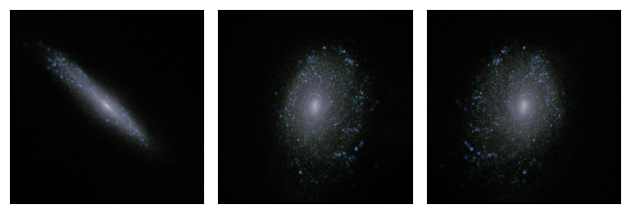

In [24]:

image_xy = sktools.get_mock_image(name, rundir, instrument_name="xy", weights=[1,2,16])
image_yz = sktools.get_mock_image(name, rundir, instrument_name="yz", weights=[1,2,16])
image_xz = sktools.get_mock_image(name, rundir, instrument_name="xz", weights=[1,2,16])

fig, axs = plt.subplots(1,3)
axs[0].imshow(image_xy, origin="lower")
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[1].imshow(image_yz, origin="lower")
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[2].imshow(image_xz, origin="lower")
axs[2].set_xticks([])
axs[2].set_yticks([])
plt.tight_layout()
plt.show()